# Readout calibration

Single-shot readout of the four qubits from the March cooldown, each prepared 1000 times in |0⟩ and in |1⟩. The assignment fidelity is `F = 1 - (P(1|0) + P(0|1)) / 2`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")

## Assignment fidelity

In [2]:
counts = {  # (read 0, read 1) after preparing |0> and after |1>
    "q0": ((962, 38), (51, 949)),
    "q1": ((941, 59), (87, 913)),
    "q2": ((978, 22), (40, 960)),
    "q3": ((903, 97), (122, 878)),
}
for qubit, (zero, one) in counts.items():
    f = 1 - (zero[1] / sum(zero) + one[0] / sum(one)) / 2
    flag = "  below 0.95" if f < 0.95 else ""
    print(f"{qubit}  F = {f:.4f}{flag}")

q0  F = 0.9555
q1  F = 0.9270  below 0.95
q2  F = 0.9690
q3  F = 0.8905  below 0.95


## Amplitude sweep on qubit 3

Qubit 3 reads worst, so its readout amplitude was swept from 0.2 to 1.0.

best amplitude 0.60: F = 0.958


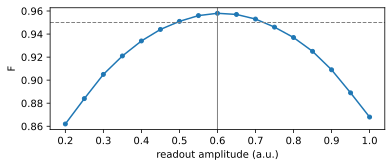

In [3]:
amps = np.linspace(0.2, 1.0, 17)
fid = np.array([0.862, 0.884, 0.905, 0.921, 0.934, 0.944, 0.951, 0.956, 0.958,
                0.957, 0.953, 0.946, 0.937, 0.925, 0.909, 0.889, 0.868])
best = amps[fid.argmax()]

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.plot(amps, fid, "o-", ms=4)
ax.axhline(0.95, color="gray", ls="--", lw=1)
ax.axvline(best, color="gray", lw=1)
ax.set(xlabel="readout amplitude (a.u.)", ylabel="F")
print(f"best amplitude {best:.2f}: F = {fid.max():.3f}")

## Next

- Set qubit 3's readout amplitude to 0.60 and take 4000 shots again
- Measure qubit 1 with the TWPA pump on